# Heart Disease Prediction ML Project
End-to-end project on EDA, preprocessing, regression, and classification.

#### **1. import libraries**

In [ ]:
# data handling
# model saving 
import joblib

# visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import (
    AdaBoostClassifier,
    AdaBoostRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)

# feature selection 
from sklearn.feature_selection import RFE, SelectKBest, VarianceThreshold, chi2

# regression models
# classification models
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge

# Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)

# Hyperparameter tuning
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from xgboost import XGBClassifier, XGBRegressor

#### **2. Load dataset**

In [4]:
df = pd.read_csv("Heart_Disease_Prediction.csv")

#### **3. Basic EDA**

In [5]:
df.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [9]:
df.tail()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence
269,67,1,4,160,286,0,2,108,1,1.5,2,3,3,Presence


In [10]:
df.sample(5)

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
104,63,1,4,130,254,0,2,147,0,1.4,2,1,7,Presence
219,44,1,2,120,220,0,0,170,0,0.0,1,0,3,Absence
89,50,1,4,150,243,0,2,128,0,2.6,2,0,7,Presence
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
123,65,0,3,160,360,0,2,151,0,0.8,1,0,3,Absence


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    str    
dtypes: float64(1), int64(12), str(1)
memo

In [15]:
df.describe()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.00000,270.000000,270.000000,270.000000
mean,54.433333,0.677778,3.174074,131.344444,249.659259,0.148148,1.022222,149.677778,0.329630,1.05000,1.585185,0.670370,4.696296
std,9.109067,0.468195,0.950090,17.861608,51.686237,0.355906,0.997891,23.165717,0.470952,1.14521,0.614390,0.943896,1.940659
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.00000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,213.000000,0.000000,0.000000,133.000000,0.000000,0.00000,1.000000,0.000000,3.000000
50%,55.000000,1.000000,3.000000,130.000000,245.000000,0.000000,2.000000,153.500000,0.000000,0.80000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,280.000000,0.000000,2.000000,166.000000,1.000000,1.60000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.20000,3.000000,3.000000,7.000000


In [74]:
print("Unique Values:\n", df.nunique())

Unique Values:
 age                         41
sex                          2
chest_pain_type              4
bp                          47
cholesterol                144
fbs_over_120                 2
ekg_results                  3
max_hr                      90
exercise_angina              2
st_depression               39
slope_of_st                  3
number_of_vessels_fluro      4
thallium                     3
heart_disease                2
dtype: int64


In [72]:
print('shape: ',df.shape)

shape:  (270, 14)


In [73]:
print("Columns:", df.columns)

Columns: Index(['age', 'sex', 'chest_pain_type', 'bp', 'cholesterol', 'fbs_over_120',
       'ekg_results', 'max_hr', 'exercise_angina', 'st_depression',
       'slope_of_st', 'number_of_vessels_fluro', 'thallium', 'heart_disease'],
      dtype='str')


In [13]:
df.dtypes

Age                          int64
Sex                          int64
Chest pain type              int64
BP                           int64
Cholesterol                  int64
FBS over 120                 int64
EKG results                  int64
Max HR                       int64
Exercise angina              int64
ST depression              float64
Slope of ST                  int64
Number of vessels fluro      int64
Thallium                     int64
Heart Disease                  str
dtype: object

In [75]:
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 age                        0
sex                        0
chest_pain_type            0
bp                         0
cholesterol                0
fbs_over_120               0
ekg_results                0
max_hr                     0
exercise_angina            0
st_depression              0
slope_of_st                0
number_of_vessels_fluro    0
thallium                   0
heart_disease              0
dtype: int64


In [76]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [77]:
print("Memory Usage:\n", df.memory_usage())

Memory Usage:
 Index                       132
age                        2160
sex                        2160
chest_pain_type            2160
bp                         2160
cholesterol                2160
fbs_over_120               2160
ekg_results                2160
max_hr                     2160
exercise_angina            2160
st_depression              2160
slope_of_st                2160
number_of_vessels_fluro    2160
thallium                   2160
heart_disease              2160
dtype: int64


#### **4. Data Cleaning**

1. remove duplicates
-> `df = df.drop_duplicates().reset_index(drop=True)` [no need]

2. Check missing values

    Optional: Fill missing numeric values with median, or drop them
    -> no missing value

3. Rename columns

In [6]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
print("\nRenamed columns to:", list(df.columns))


Renamed columns to: ['age', 'sex', 'chest_pain_type', 'bp', 'cholesterol', 'fbs_over_120', 'ekg_results', 'max_hr', 'exercise_angina', 'st_depression', 'slope_of_st', 'number_of_vessels_fluro', 'thallium', 'heart_disease']


4. Convert target column to binary if needed

In [8]:
df['heart_disease'] = np.where(df['heart_disease'] == 'Presence',1,0)
df

,age,sex,chest_pain_type,bp,cholesterol,fbs_over_120,ekg_results,max_hr,exercise_angina,st_depression,slope_of_st,number_of_vessels_fluro,thallium,heart_disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,0
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,0
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,0
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,0


5. Check incorrect values

In [9]:
df['bp'] = df['bp'].clip(lower=40, upper=250)              # Blood pressure bounds
df['cholesterol'] = df['cholesterol'].clip(lower=80, upper=600)  # Cholesterol bounds
df['max_hr'] = df['max_hr'].clip(lower=50, upper=220) 
df

,age,sex,chest_pain_type,bp,cholesterol,fbs_over_120,ekg_results,max_hr,exercise_angina,st_depression,slope_of_st,number_of_vessels_fluro,thallium,heart_disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,0
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,0
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,0
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,0


Checking correlation between columns

In [35]:
print(df.corr()["heart_disease"].abs().sort_values(ascending=False))

heart_disease              1.000000
thallium                   0.525020
number_of_vessels_fluro    0.455336
exercise_angina            0.419303
max_hr                     0.418514
st_depression              0.417967
chest_pain_type            0.417436
slope_of_st                0.337616
sex                        0.297721
age                        0.212322
ekg_results                0.182091
bp                         0.155383
cholesterol                0.118021
fbs_over_120               0.016319
Name: heart_disease, dtype: float64


#### **5. VISUALIZATION ANALYSIS**

**1. Univariate Analysis**

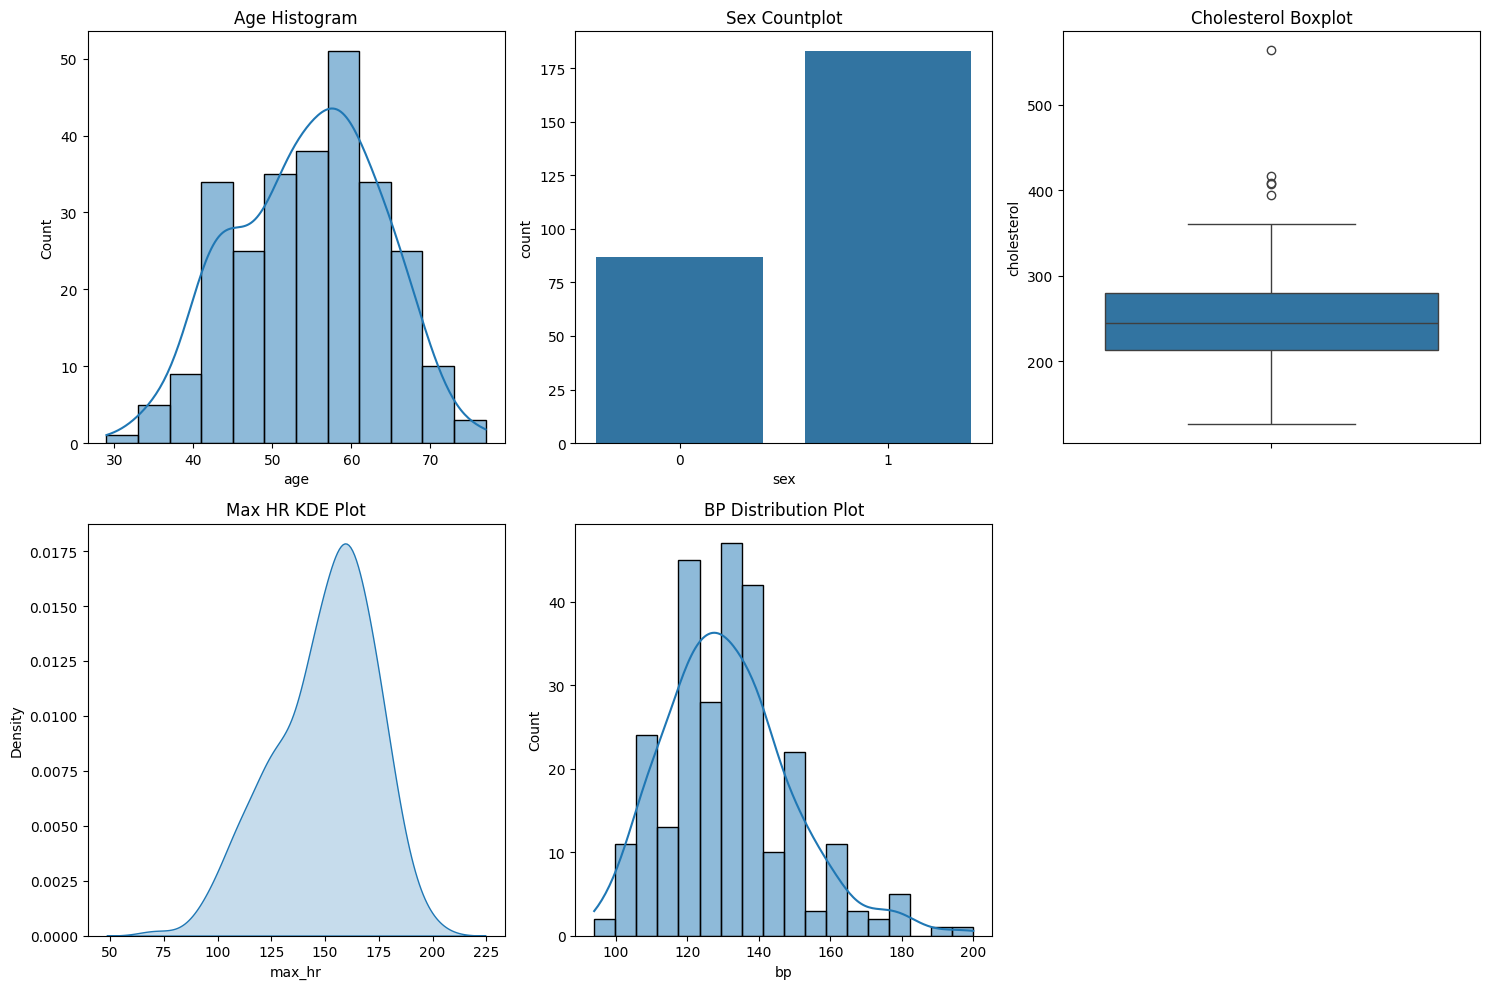

In [86]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
sns.histplot(df["age"], kde=True)
plt.title("Age Histogram")

plt.subplot(2, 3, 2)
sns.countplot(x="sex", data=df)
plt.title("Sex Countplot")

plt.subplot(2, 3, 3)
sns.boxplot(y=df["cholesterol"])
plt.title("Cholesterol Boxplot")

plt.subplot(2, 3, 4)
sns.kdeplot(df["max_hr"], fill=True)
plt.title("Max HR KDE Plot")

plt.subplot(2, 3, 5)
sns.histplot(df["bp"], kde=True)
plt.title("BP Distribution Plot")

plt.tight_layout()
plt.show()

**6. Bivariate Analysis**

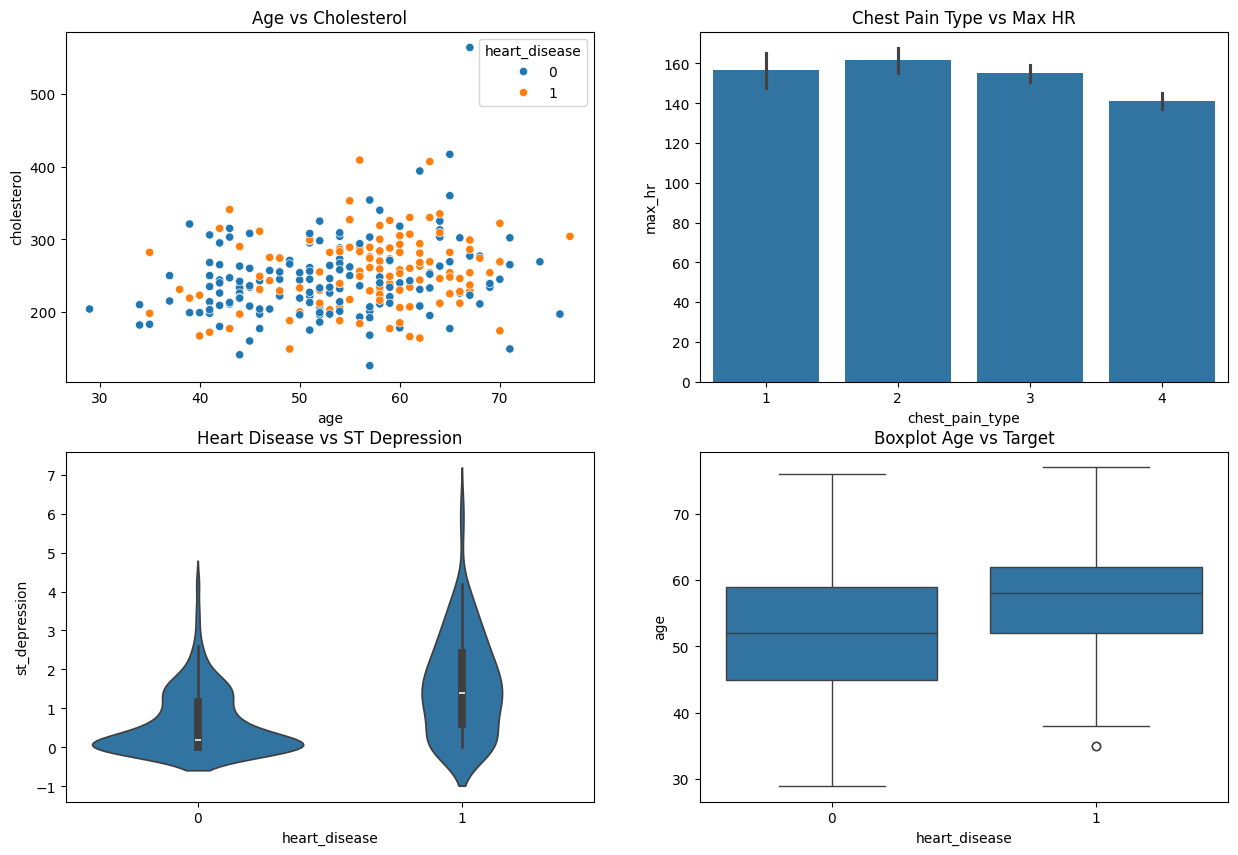

In [92]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
sns.scatterplot(x="age", y="cholesterol", hue="heart_disease", data=df)
plt.title("Age vs Cholesterol")

plt.subplot(2, 2, 2)
sns.barplot(data=df,x="chest_pain_type", y="max_hr")
plt.title("Chest Pain Type vs Max HR")

plt.subplot(2, 2, 3)
sns.violinplot(data=df,x="heart_disease", y="st_depression")
plt.title("Heart Disease vs ST Depression")

plt.subplot(2, 2, 4)
sns.boxplot(data=df,x="heart_disease", y="age")
plt.title("Boxplot Age vs Target")

plt.show()

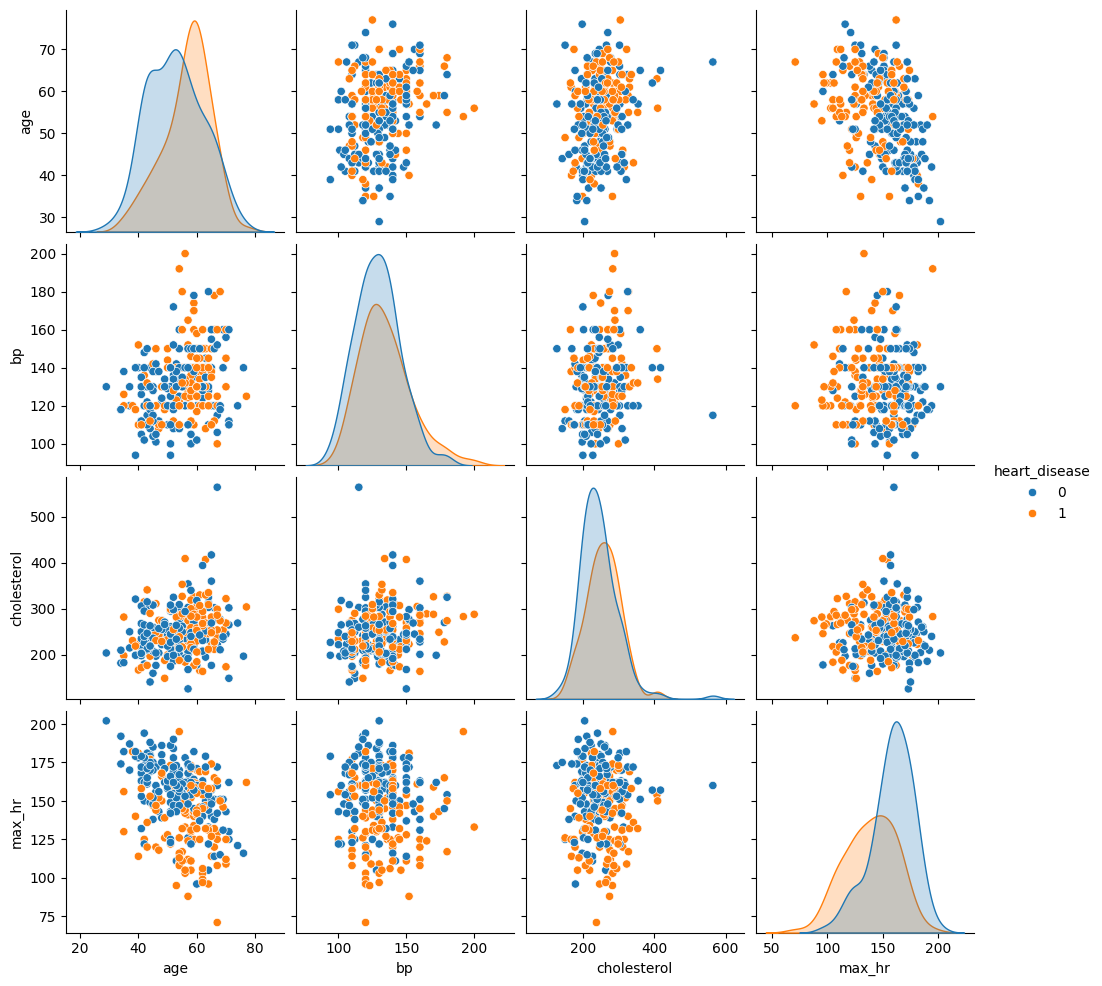

In [89]:
# Pairplot (Selected columns to save computation time)
sns.pairplot(
    df[["age", "bp", "cholesterol", "max_hr", "heart_disease"]],
    hue="heart_disease",
)
plt.show()

In [ ]:
print("--- UNIQUE PER COLUMN ---")

selected_features = ['sex', 'chest_pain_type','fbs_over_120','ekg_results', 'exercise_angina', 'slope_of_st', 'number_of_vessels_fluro', 'thallium', 'heart_disease']
for col in df[selected_features].columns:
    print(f"\nColumn: {col}")
    print(df[col].unique())


--- UNIQUE ARRAYS PER COLUMN ---

Column: sex
[1 0]

Column: chest_pain_type
[4 3 2 1]

Column: fbs_over_120
[0 1]

Column: ekg_results
[2 0 1]

Column: exercise_angina
[0 1]

Column: slope_of_st
[2 1 3]

Column: number_of_vessels_fluro
[3 0 1 2]

Column: thallium
[3 7 6]

Column: heart_disease
[1 0]


**3. SEPARATE VISUALIZATION ANALYSIS**

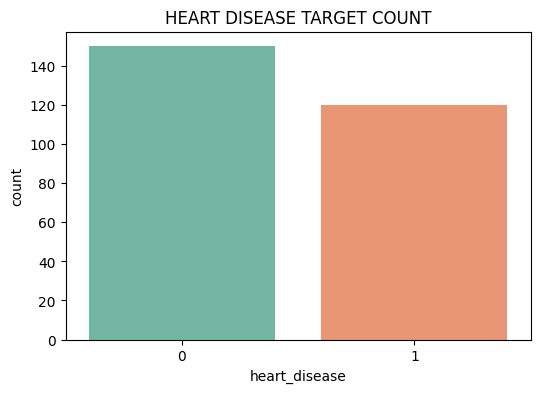

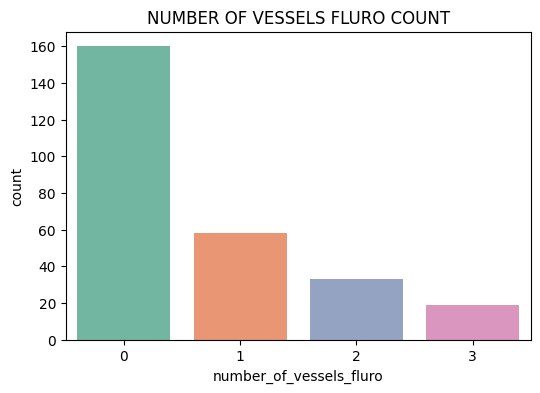

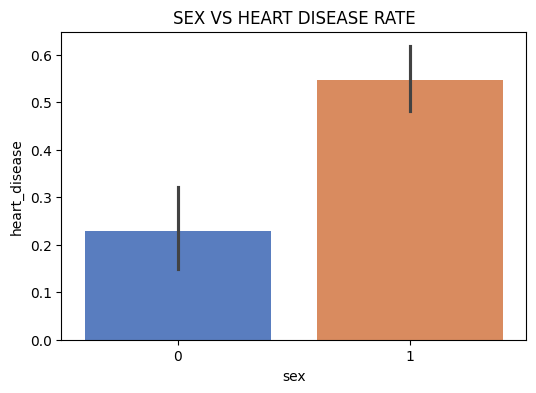

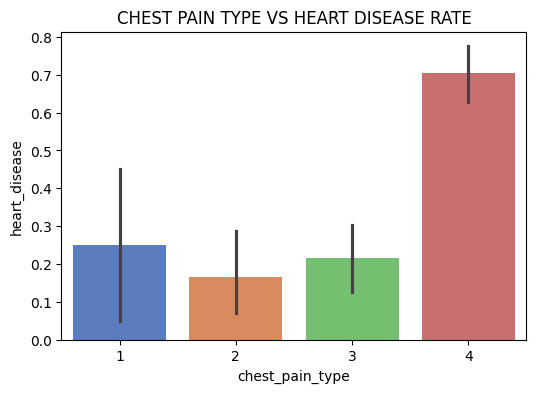

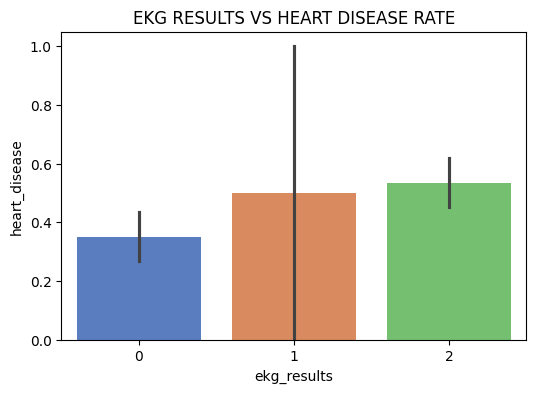

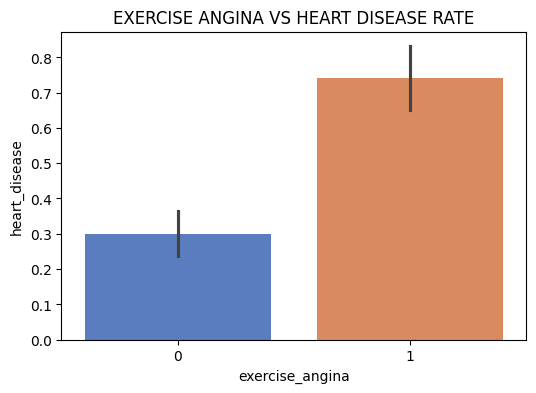

In [ ]:
# --- 1. COUNTPLOTS (Target & Numbers) ---
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="heart_disease", hue="heart_disease", legend=False, palette="Set2")
plt.title("HEART DISEASE TARGET COUNT")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="number_of_vessels_fluro", hue="number_of_vessels_fluro", legend=False, palette="Set2")
plt.title("NUMBER OF VESSELS FLURO COUNT")
plt.show()


# --- 2. BARPLOTS (Features vs Target) ---

# Sex vs Target
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="sex", y="heart_disease", hue="sex", legend=False, palette="muted")
plt.title("SEX VS HEART DISEASE RATE")
plt.show()

# Chest Pain vs Target
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="chest_pain_type", y="heart_disease", hue="chest_pain_type", legend=False, palette="muted")
plt.title("CHEST PAIN TYPE VS HEART DISEASE RATE")
plt.show()

# EKG Results vs Target
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="ekg_results", y="heart_disease", hue="ekg_results", legend=False, palette="muted")
plt.title("EKG RESULTS VS HEART DISEASE RATE")
plt.show()

# Exercise Angina vs Target
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="exercise_angina", y="heart_disease", hue="exercise_angina", legend=False, palette="muted")
plt.title("EXERCISE ANGINA VS HEART DISEASE RATE")
plt.show()


**4. Correlation Analysis**

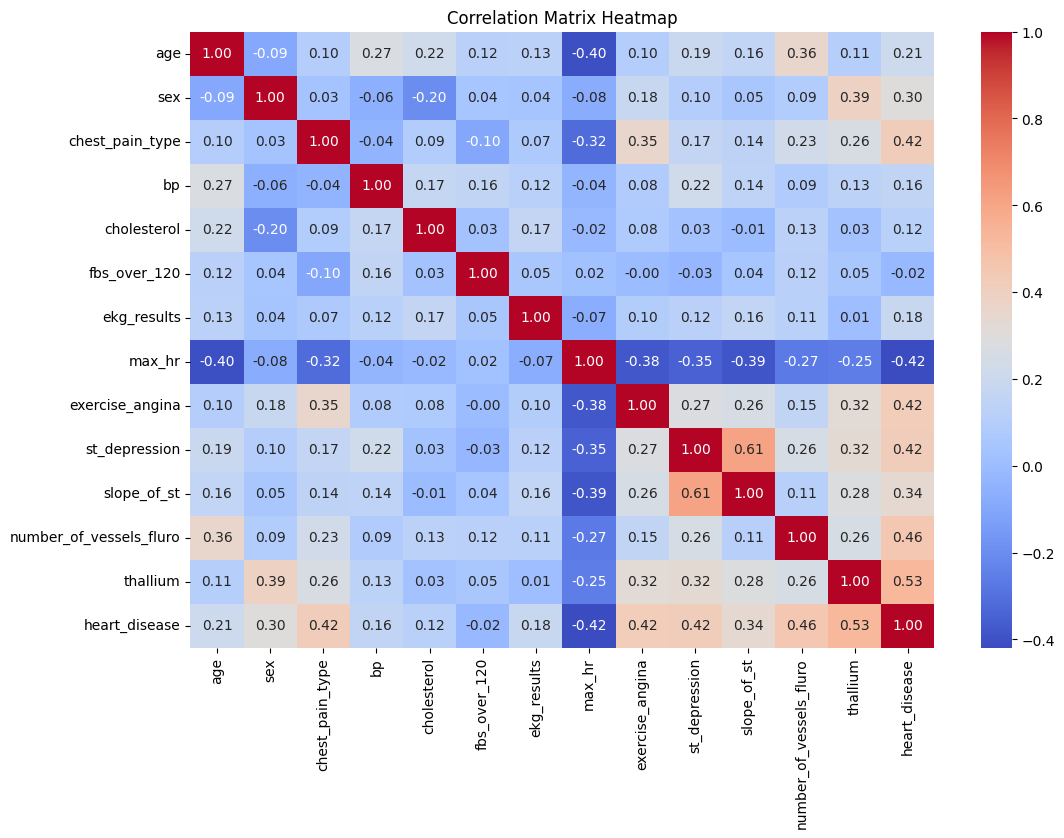

In [108]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

#### **6. Outlier Detection**

In [109]:
print("\n--- 8. OUTLIER DETECTION ---")
# Method 1: IQR Method on Cholesterol
Q1 = df["cholesterol"].quantile(0.25)
Q3 = df["cholesterol"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_outliers = df[
    (df["cholesterol"] < lower_bound) | (df["cholesterol"] > upper_bound)
]
print(f"IQR Method: Found {len(iqr_outliers)} outliers in Cholesterol.")

#------------------------------------------------------
# Method 2: Z-score Method on Max HR
z_scores = np.abs(stats.zscore(df["max_hr"]))
z_outliers = df[z_scores > 3]
print(f"Z-score Method: Found {len(z_outliers)} outliers in Max HR.")




--- 8. OUTLIER DETECTION ---
IQR Method: Found 5 outliers in Cholesterol.
Z-score Method: Found 1 outliers in Max HR.


#### **7. Feature Engineering**

In [117]:
df['high_pulse_pressure'] = (df['bp'] > 140).astype(int)

df['age_group'] = pd.cut(
    df['age'], 
    bins=[0, 40, 50, np.inf], 
    labels=[0, 1, 2]
).astype(int)
df.head()

# Creating a compounding risk metric: High Cholesterol (>240) AND High Blood Sugar (fbs=1)
df['metabolic_risk'] = ((df['cholesterol'] > 240) & (df['fbs_over_120'] == 1)).astype(int)

risk_points = (
    (df['age'] > 50).astype(int) +
    (df['sex'] == 1).astype(int) +
    (df['bp'] > 130).astype(int) +
    (df['cholesterol'] > 240).astype(int) +
    (df['exercise_angina'] == 1).astype(int)
)
df['disease_chance_%'] = round((risk_points / 5) * 80 + 10, 2)


#### **8. Train-test-split**

In [118]:
X = df.drop(columns=['heart_disease','disease_chance_%'])
y_reg = df["disease_chance_%"]
y_cls = df["heart_disease"]

X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)
X_train, X_test, y_train_cls, y_test_cls = train_test_split(
    X, y_cls, test_size=0.2, random_state=42
)

#### **9. Feature scaling & encoding**

In [119]:
numeric_cols = ["age", "bp", "cholesterol", "max_hr", "st_depression"]
categorical_cols = ["sex", "chest_pain_type", "fbs_over_120", "ekg_results", "exercise_angina", "slope_of_st", "number_of_vessels_fluro", "thallium","high_pulse_pressure", "age_group", "metabolic_risk"]

scaler_advanced = StandardScaler()
X_train_num_scaled = scaler_advanced.fit_transform(X_train[numeric_cols])
X_test_num_scaled = scaler_advanced.transform(X_test[numeric_cols])

#One hot encoder -> already encoded

# 5. Combine scaled numeric data and unscaled categorical data side-by-side
# (np.hstack glues the columns together perfectly into a single matrix)         # Convert to numpy array ->X_train[categorical_cols].values
X_train_advanced = np.hstack((X_train_num_scaled, X_train[categorical_cols].values))
X_test_advanced = np.hstack((X_test_num_scaled, X_test[categorical_cols].values))

print("Advanced Separate Preprocessing Complete!")
print("Shape of final Train matrix:", X_train_advanced.shape)
print("Shape of final Test matrix :", X_test_advanced.shape)

Advanced Separate Preprocessing Complete!
Shape of final Train matrix: (216, 16)
Shape of final Test matrix : (54, 16)


#### **10. Train Regression Models**

In [120]:
# 1. Linear Regression 
lr_reg = LinearRegression()
lr_reg.fit(X_train_advanced, y_train_reg)

# 1. Ridge Regression 
rg_reg = Ridge()
rg_reg.fit(X_train_advanced, y_train_reg)

# 1. Lasso Regression 
ls_reg = Lasso()
ls_reg.fit(X_train_advanced, y_train_reg)

# 2. Decision Tree Regressor
dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(X_train_advanced, y_train_reg)

# 3. Random Forest Regressor
rf_reg = RandomForestRegressor(random_state=42)
rf_reg.fit(X_train_advanced, y_train_reg)

# 4. Gradient Boosting Regressor
gb_reg = GradientBoostingRegressor(random_state=42)
gb_reg.fit(X_train_advanced, y_train_reg)

# 5. XgBoost Regressor
xg_reg = XGBRegressor(random_state=42)
xg_reg.fit(X_train_advanced, y_train_reg)

# 5. AdaBoost Regressor
ada_reg = AdaBoostRegressor(random_state=42)
ada_reg.fit(X_train_advanced, y_train_reg)

# 7. Support Vector Regressor (SVR instead of SVC)
svm_reg = SVR(kernel='rbf')
svm_reg.fit(X_train_advanced, y_train_reg)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


#### **11. Regression Models Evaluation**

In [121]:
# 1. Linear Regression Evaluation
y_pred_lr = lr_reg.predict(X_test_advanced)
lr_mae = round(mean_absolute_error(y_test_reg, y_pred_lr), 4)
lr_mse = round(mean_squared_error(y_test_reg, y_pred_lr), 4)
lr_r2  = round(r2_score(y_test_reg, y_pred_lr) * 100, 2)

print("\n==========================================")
print("1. LINEAR REGRESSION PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {lr_mae}")
print(f"MSE:       {lr_mse}")
print(f"R2 Score:  {lr_r2}%")


# 2. Ridge Regression Evaluation
y_pred_rg = rg_reg.predict(X_test_advanced)
rg_mae = round(mean_absolute_error(y_test_reg, y_pred_rg), 4)
rg_mse = round(mean_squared_error(y_test_reg, y_pred_rg), 4)
rg_r2  = round(r2_score(y_test_reg, y_pred_rg) * 100, 2)

print("\n==========================================")
print("2. RIDGE REGRESSION PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {rg_mae}")
print(f"MSE:       {rg_mse}")
print(f"R2 Score:  {rg_r2}%")


# 3. Lasso Regression Evaluation
y_pred_ls = ls_reg.predict(X_test_advanced)
ls_mae = round(mean_absolute_error(y_test_reg, y_pred_ls), 4)
ls_mse = round(mean_squared_error(y_test_reg, y_pred_ls), 4)
ls_r2  = round(r2_score(y_test_reg, y_pred_ls) * 100, 2)

print("\n==========================================")
print("3. LASSO REGRESSION PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {ls_mae}")
print(f"MSE:       {ls_mse}")
print(f"R2 Score:  {ls_r2}%")


# 4. Decision Tree Regressor Evaluation
y_pred_dt = dt_reg.predict(X_test_advanced)
dt_mae = round(mean_absolute_error(y_test_reg, y_pred_dt), 4)
dt_mse = round(mean_squared_error(y_test_reg, y_pred_dt), 4)
dt_r2  = round(r2_score(y_test_reg, y_pred_dt) * 100, 2)

print("\n==========================================")
print("4. DECISION TREE REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {dt_mae}")
print(f"MSE:       {dt_mse}")
print(f"R2 Score:  {dt_r2}%")


# 5. Random Forest Regressor Evaluation
y_pred_rf = rf_reg.predict(X_test_advanced)
rf_mae = round(mean_absolute_error(y_test_reg, y_pred_rf), 4)
rf_mse = round(mean_squared_error(y_test_reg, y_pred_rf), 4)
rf_r2  = round(r2_score(y_test_reg, y_pred_rf) * 100, 2)

print("\n==========================================")
print("5. RANDOM FOREST REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {rf_mae}")
print(f"MSE:       {rf_mse}")
print(f"R2 Score:  {rf_r2}%")


# 6. Gradient Boosting Regressor Evaluation
y_pred_gb = gb_reg.predict(X_test_advanced)
gb_mae = round(mean_absolute_error(y_test_reg, y_pred_gb), 4)
gb_mse = round(mean_squared_error(y_test_reg, y_pred_gb), 4)
gb_r2  = round(r2_score(y_test_reg, y_pred_gb) * 100, 2)

print("\n==========================================")
print("6. GRADIENT BOOSTING REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {gb_mae}")
print(f"MSE:       {gb_mse}")
print(f"R2 Score:  {gb_r2}%")


# 7. XGBoost Regressor Evaluation
y_pred_xg = xg_reg.predict(X_test_advanced)
xg_mae = round(mean_absolute_error(y_test_reg, y_pred_xg), 4)
xg_mse = round(mean_squared_error(y_test_reg, y_pred_xg), 4)
xg_r2  = round(r2_score(y_test_reg, y_pred_xg) * 100, 2)

print("\n==========================================")
print("7. XGBOOST REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {xg_mae}")
print(f"MSE:       {xg_mse}")
print(f"R2 Score:  {xg_r2}%")


# 8. AdaBoost Regressor Evaluation
y_pred_ada = ada_reg.predict(X_test_advanced)
ada_mae = round(mean_absolute_error(y_test_reg, y_pred_ada), 4)
ada_mse = round(mean_squared_error(y_test_reg, y_pred_ada), 4)
ada_r2  = round(r2_score(y_test_reg, y_pred_ada) * 100, 2)

print("\n==========================================")
print("8. ADABOOST REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {ada_mae}")
print(f"MSE:       {ada_mse}")
print(f"R2 Score:  {ada_r2}%")


# 9. Support Vector Regressor Evaluation
y_pred_svm = svm_reg.predict(X_test_advanced)
svm_mae = round(mean_absolute_error(y_test_reg, y_pred_svm), 4)
svm_mse = round(mean_squared_error(y_test_reg, y_pred_svm), 4)
svm_r2  = round(r2_score(y_test_reg, y_pred_svm) * 100, 2)

print("\n==========================================")
print("9. SUPPORT VECTOR REGRESSOR PERFORMANCE")
print("----------+------------------------------")
print(f"MAE:       {svm_mae}")
print(f"MSE:       {svm_mse}")
print(f"R2 Score:  {svm_r2}%")


1. LINEAR REGRESSION PERFORMANCE
----------+------------------------------
MAE:       6.8061
MSE:       68.5187
R2 Score:  78.53%

2. RIDGE REGRESSION PERFORMANCE
----------+------------------------------
MAE:       6.6473
MSE:       65.5233
R2 Score:  79.47%

3. LASSO REGRESSION PERFORMANCE
----------+------------------------------
MAE:       5.9351
MSE:       51.4099
R2 Score:  83.89%

4. DECISION TREE REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       1.1852
MSE:       18.963
R2 Score:  94.06%

5. RANDOM FOREST REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       2.3763
MSE:       12.5013
R2 Score:  96.08%

6. GRADIENT BOOSTING REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       0.7065
MSE:       2.3561
R2 Score:  99.26%

7. XGBOOST REGRESSOR PERFORMANCE
----------+------------------------------
MAE:       1.1424
MSE:       14.0406
R2 Score:  95.6%

8. ADABOOST REGRESSOR PERFORMANCE
----------+--------------------

**Model Accuracy comparision**

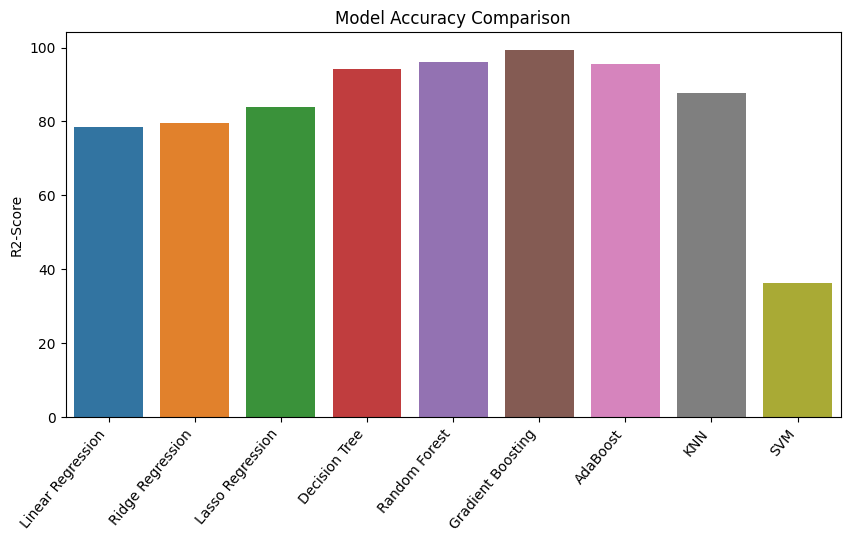

In [122]:
r2 = [lr_r2,rg_r2,ls_r2,dt_r2,rf_r2,gb_r2,xg_r2,ada_r2,svm_r2]
algorithms = ["Linear Regression","Ridge Regression","Lasso Regression","Decision Tree","Random Forest","Gradient Boosting","AdaBoost","KNN","SVM"]    

# accuracy score
plt.figure(figsize=(10, 5))
sns.barplot(x=algorithms,y=r2,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("R2-Score")
plt.title("Model Accuracy Comparison")
plt.show()

#### **12. Train Classification Models**

In [123]:
# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_advanced, y_train_cls)

# 2. Decision Tree (Trees do not require scaling, but you can pass it anyway)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_advanced, y_train_cls)

# 3. Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_advanced, y_train_cls)

# 4. Gradient Boosting
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_advanced, y_train_cls)

# 5. XgBoost Regressor
xg = XGBClassifier(random_state=42)
xg.fit(X_train_advanced, y_train_cls)

# 6. AdaBoost
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train_advanced, y_train_cls)

# 7. KNN
knn = KNeighborsClassifier()
knn.fit(X_train_advanced, y_train_cls)

# 8. SVM
svm = SVC(probability=True, random_state=42)
svm.fit(X_train_advanced, y_train_cls)

# 9. Naive Bayes
nb = GaussianNB()
nb.fit(X_train_advanced, y_train_cls)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


#### **13. Classification Models Evaluations**

In [124]:
# 1. Logistic Regression
y_pred_lr = lr.predict(X_test_advanced)
lr_score = round(accuracy_score(y_test_cls, y_pred_lr)*100,2)
lr_f1 = round(f1_score(y_test_cls, y_pred_lr)*100,2)
lr_precision = round(precision_score(y_test_cls, y_pred_lr)*100,2)
lr_recall = round(recall_score(y_test_cls, y_pred_lr)*100,2)
cm_lr = confusion_matrix(y_test_cls, y_pred_lr)

print("\n==========================================")
print("1. LOGISTIC REGRESSION PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {lr_score}%")
print(f"F1-Score:          {lr_f1}%")
print(f"Precision:         {lr_precision}%")
print(f"Recall:            {lr_recall}%")
print("Confusion Matrix:\n", cm_lr)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_lr))

# ==========================================
# 2. Decision Tree
y_pred_dt = dt.predict(X_test_advanced)
dt_score = round(accuracy_score(y_test_cls, y_pred_dt) * 100, 2)
dt_f1 = round(f1_score(y_test_cls, y_pred_dt) * 100, 2)
dt_precision = round(precision_score(y_test_cls, y_pred_dt) * 100, 2)
dt_recall = round(recall_score(y_test_cls, y_pred_dt) * 100, 2)
cm_dt = confusion_matrix(y_test_cls, y_pred_dt)

print("\n==========================================")
print("2. DECISION TREE PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {dt_score}%")
print(f"F1-Score:          {dt_f1}%")
print(f"Precision:         {dt_precision}%")
print(f"Recall:            {dt_recall}%")
print("Confusion Matrix:\n", cm_dt)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_dt))


# ==========================================
# 3. Random Forest
y_pred_rf = rf.predict(X_test_advanced)
rf_score = round(accuracy_score(y_test_cls, y_pred_rf) * 100, 2)
rf_f1 = round(f1_score(y_test_cls, y_pred_rf) * 100, 2)
rf_precision = round(precision_score(y_test_cls, y_pred_rf) * 100, 2)
rf_recall = round(recall_score(y_test_cls, y_pred_rf) * 100, 2)
cm_rf = confusion_matrix(y_test_cls, y_pred_rf)

print("\n==========================================")
print("3. RANDOM FOREST PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {rf_score}%")
print(f"F1-Score:          {rf_f1}%")
print(f"Precision:         {rf_precision}%")
print(f"Recall:            {rf_recall}%")
print("Confusion Matrix:\n", cm_rf)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_rf))

# ==========================================
# 4. Gradient Boosting
y_pred_gb = gb.predict(X_test_advanced)
gb_score = round(accuracy_score(y_test_cls, y_pred_gb) * 100, 2)
gb_f1 = round(f1_score(y_test_cls, y_pred_gb) * 100, 2)
gb_precision = round(precision_score(y_test_cls, y_pred_gb) * 100, 2)
gb_recall = round(recall_score(y_test_cls, y_pred_gb) * 100, 2)
cm_gb = confusion_matrix(y_test_cls, y_pred_gb)

print("\n==========================================")
print("4. GRADIENT BOOSTING PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {gb_score}%")
print(f"F1-Score:          {gb_f1}%")
print(f"Precision:         {gb_precision}%")
print(f"Recall:            {gb_recall}%")
print("Confusion Matrix:\n", cm_gb)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_gb))

# ==========================================
# 5. XgBoosting
y_pred_xg = xg.predict(X_test_advanced)
xg_score = round(accuracy_score(y_test_cls, y_pred_xg) * 100, 2)
xg_f1 = round(f1_score(y_test_cls, y_pred_xg) * 100, 2)
xg_precision = round(precision_score(y_test_cls, y_pred_xg) * 100, 2)
xg_recall = round(recall_score(y_test_cls, y_pred_xg) * 100, 2)
cm_xg = confusion_matrix(y_test_cls, y_pred_xg)

print("\n==========================================")
print("5. GRADIENT BOOSTING PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {xg_score}%")
print(f"F1-Score:          {xg_f1}%")
print(f"Precision:         {xg_precision}%")
print(f"Recall:            {xg_recall}%")
print("Confusion Matrix:\n", cm_xg)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_xg))

# ==========================================
# 6. AdaBoost
y_pred_ada = ada.predict(X_test_advanced)
ada_score = round(accuracy_score(y_test_cls, y_pred_ada) * 100, 2)
ada_f1 = round(f1_score(y_test_cls, y_pred_ada) * 100, 2)
ada_precision = round(precision_score(y_test_cls, y_pred_ada) * 100, 2)
ada_recall = round(recall_score(y_test_cls, y_pred_ada) * 100, 2)
cm_ada = confusion_matrix(y_test_cls, y_pred_ada)

print("\n==========================================")
print("6. ADABOOST PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {ada_score}%")
print(f"F1-Score:          {ada_f1}%")
print(f"Precision:         {ada_precision}%")
print(f"Recall:            {ada_recall}%")
print("Confusion Matrix:\n", cm_ada)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_ada))


# ==========================================
# 7. KNN
y_pred_knn = knn.predict(X_test_advanced)
knn_score = round(accuracy_score(y_test_cls, y_pred_knn) * 100, 2)
knn_f1 = round(f1_score(y_test_cls, y_pred_knn) * 100, 2)
knn_precision = round(precision_score(y_test_cls, y_pred_knn) * 100, 2)
knn_recall = round(recall_score(y_test_cls, y_pred_knn) * 100, 2)
cm_knn = confusion_matrix(y_test_cls, y_pred_knn)

print("\n==========================================")
print("7. KNN PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {knn_score}%")
print(f"F1-Score:          {knn_f1}%")
print(f"Precision:         {knn_precision}%")
print(f"Recall:            {knn_recall}%")
print("Confusion Matrix:\n", cm_knn)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_knn))


# ==========================================
# 8. SVM
y_pred_svm = svm.predict(X_test_advanced)
svm_score = round(accuracy_score(y_test_cls, y_pred_svm) * 100, 2)
svm_f1 = round(f1_score(y_test_cls, y_pred_svm) * 100, 2)
svm_precision = round(precision_score(y_test_cls, y_pred_svm) * 100, 2)
svm_recall = round(recall_score(y_test_cls, y_pred_svm) * 100, 2)
cm_svm = confusion_matrix(y_test_cls, y_pred_svm)

print("\n==========================================")
print("8. SVM PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {svm_score}%")
print(f"F1-Score:          {svm_f1}%")
print(f"Precision:         {svm_precision}%")
print(f"Recall:            {svm_recall}%")
print("Confusion Matrix:\n", cm_svm)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_svm))


# ==========================================
# 9. Naive Bayes
y_pred_nb = nb.predict(X_test_advanced)
nb_score = round(accuracy_score(y_test_cls, y_pred_nb) * 100, 2)
nb_f1 = round(f1_score(y_test_cls, y_pred_nb) * 100, 2)
nb_precision = round(precision_score(y_test_cls, y_pred_nb) * 100, 2)
nb_recall = round(recall_score(y_test_cls, y_pred_nb) * 100, 2)
cm_nb = confusion_matrix(y_test_cls, y_pred_nb)

print("\n==========================================")
print("9. NAIVE BAYES PERFORMANCE")
print("------------------+-----------------------")
print(f"Accuracy:          {nb_score}%")
print(f"F1-Score:          {nb_f1}%")
print(f"Precision:         {nb_precision}%")
print(f"Recall:            {nb_recall}%")
print("Confusion Matrix:\n", cm_nb)
print("Classification Report:\n", classification_report(y_test_cls, y_pred_nb))


1. LOGISTIC REGRESSION PERFORMANCE
------------------+-----------------------
Accuracy:          92.59%
F1-Score:          90.0%
Precision:         94.74%
Recall:            85.71%
Confusion Matrix:
 [[32  1]
 [ 3 18]]
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.97      0.94        33
           1       0.95      0.86      0.90        21

    accuracy                           0.93        54
   macro avg       0.93      0.91      0.92        54
weighted avg       0.93      0.93      0.93        54


2. DECISION TREE PERFORMANCE
------------------+-----------------------
Accuracy:          74.07%
F1-Score:          69.57%
Precision:         64.0%
Recall:            76.19%
Confusion Matrix:
 [[24  9]
 [ 5 16]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.73      0.77        33
           1       0.64      0.76      0.70        21

    accuracy               

**Model Accuracy comparison**

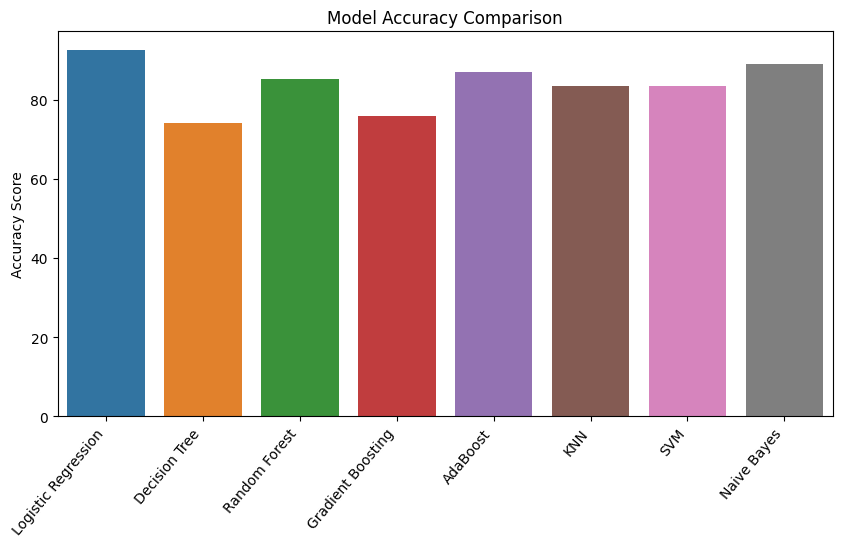

In [125]:
scores = [lr_score,dt_score,rf_score,gb_score,ada_score,knn_score,svm_score,nb_score]
f1 = [lr_f1,dt_f1,rf_f1,gb_f1,ada_f1,knn_f1,svm_f1,nb_f1]
algorithms = ["Logistic Regression","Decision Tree","Random Forest","Gradient Boosting","AdaBoost","KNN","SVM","Naive Bayes"]    

# accuracy score
plt.figure(figsize=(10, 5))
sns.barplot(x=algorithms,y=scores,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("Accuracy Score")
plt.title("Model Accuracy Comparison")
plt.show()

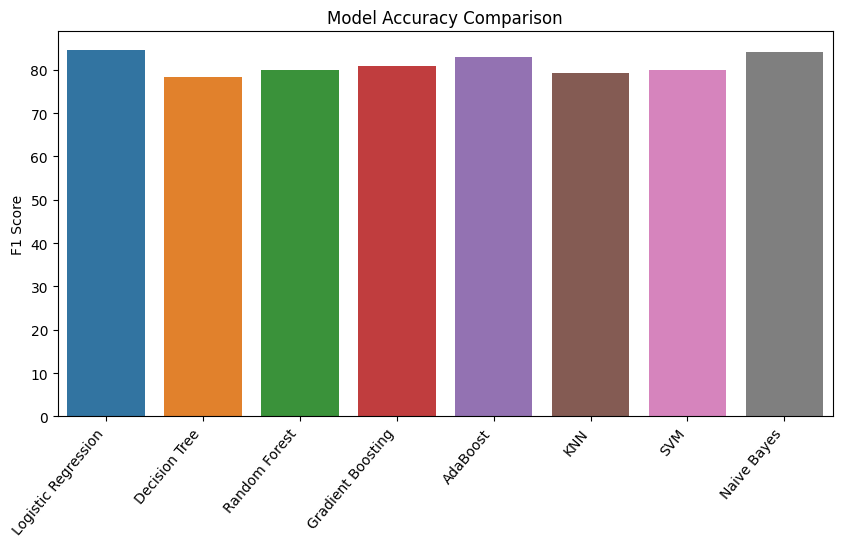

In [ ]:
# f1 score
plt.figure(figsize=(10, 5))
sns.barplot(x=algorithms,y=f1,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("F1 Score")
plt.title("Model Accuracy Comparison")
plt.show()

#### **14. Cross Validation**

In [140]:
print("\n--- 5-FOLD CROSS VALIDATION (ACCURACY %) ---")

# 1. Logistic Regression CV
lr_cv = cross_val_score(lr, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Logistic Regression Mean CV: {round(lr_cv.mean() * 100, 2)}% (+/- {round(lr_cv.std() * 100, 2)}%)")

# 2. Decision Tree CV
dt_cv = cross_val_score(dt, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Decision Tree Mean CV:       {round(dt_cv.mean() * 100, 2)}% (+/- {round(dt_cv.std() * 100, 2)}%)")

# 3. Random Forest CV
rf_cv = cross_val_score(rf, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Random Forest Mean CV:       {round(rf_cv.mean() * 100, 2)}% (+/- {round(rf_cv.std() * 100, 2)}%)")

# 4. Gradient Boosting CV
gb_cv = cross_val_score(gb, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Gradient Boosting Mean CV:   {round(gb_cv.mean() * 100, 2)}% (+/- {round(gb_cv.std() * 100, 2)}%)")

# 5. AdaBoost CV
ada_cv = cross_val_score(ada, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"AdaBoost Mean CV:            {round(ada_cv.mean() * 100, 2)}% (+/- {round(ada_cv.std() * 100, 2)}%)")

# 6. KNN CV
knn_cv = cross_val_score(knn, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"KNN Mean CV:                 {round(knn_cv.mean() * 100, 2)}% (+/- {round(knn_cv.std() * 100, 2)}%)")

# 7. SVM CV
svm_cv = cross_val_score(svm, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"SVM Mean CV:                 {round(svm_cv.mean() * 100, 2)}% (+/- {round(svm_cv.std() * 100, 2)}%)")

# 8. Naive Bayes CV
nb_cv = cross_val_score(nb, X_train_advanced, y_train_cls, cv=5, scoring="accuracy")
print(f"Naive Bayes Mean CV:         {round(nb_cv.mean() * 100, 2)}% (+/- {round(nb_cv.std() * 100, 2)}%)")


--- 5-FOLD CROSS VALIDATION (ACCURACY %) ---
Logistic Regression Mean CV: 83.36% (+/- 5.66%)
Decision Tree Mean CV:       69.01% (+/- 6.36%)
Random Forest Mean CV:       82.44% (+/- 4.36%)
Gradient Boosting Mean CV:   74.57% (+/- 3.63%)
AdaBoost Mean CV:            80.57% (+/- 2.65%)
KNN Mean CV:                 79.66% (+/- 5.61%)
SVM Mean CV:                 81.05% (+/- 7.6%)
Naive Bayes Mean CV:         81.51% (+/- 5.75%)


#### **15. Feature Selection**

In [141]:
print("\n--- FEATURE SELECTION ---")

# 1.Variance Threshold -> Checks low-variance features on your raw unscaled training columns
selector_vt = VarianceThreshold(threshold=0.1)
X_vt = selector_vt.fit_transform(X_train)
print(f"Variance Threshold: Reduced columns shape to {X_vt.shape}")

# Get names of columns that pass the threshold
vt_names = X_train.columns[selector_vt.get_support()].tolist()
print("Variance Threshold Features:", vt_names)
#----

# 2. Pick top 5 columns using Chi-Square (for classification)
X_positive = MinMaxScaler().fit_transform(X_train)
selector_kb = SelectKBest(score_func=chi2, k=5)
X_kb = selector_kb.fit_transform(X_positive, y_train_cls)
print(f"\nSelectKBest (Chi-Square): Selected top 5 columns shape to {X_kb.shape}")

# Get names of the top 5 classification features
kb_names = X_train.columns[selector_kb.get_support()].tolist()
print("SelectKBest Top 5 Features:", kb_names)
#----

# 3. Pick top 5 columns using RFE elimination (for regression)
rfe = RFE(estimator=LinearRegression(), n_features_to_select=5)
X_rfe = rfe.fit_transform(X_train_advanced, y_train_reg)
print(f"\nRFE: Extracted top 5 features shape to {X_rfe.shape}")

# Map chosen columns back to our combined advanced features list
advanced_columns = numeric_cols + categorical_cols
rfe_names = [advanced_columns[i] for i, chosen in enumerate(rfe.support_) if chosen]
print("RFE Top 5 Regressor Features:", rfe_names)
#----

# Compress all columns down to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_advanced)
print(f"\nPCA shape: {X_pca.shape}")
print(f"PCA explained variance ratio: {pca.explained_variance_ratio_}")



--- FEATURE SELECTION ---
Variance Threshold: Reduced columns shape to (216, 15)
Variance Threshold Features: ['age', 'sex', 'chest_pain_type', 'bp', 'cholesterol', 'fbs_over_120', 'ekg_results', 'max_hr', 'exercise_angina', 'st_depression', 'slope_of_st', 'number_of_vessels_fluro', 'thallium', 'high_pulse_pressure', 'age_group']

SelectKBest (Chi-Square): Selected top 5 columns shape to (216, 5)
SelectKBest Top 5 Features: ['exercise_angina', 'st_depression', 'slope_of_st', 'number_of_vessels_fluro', 'thallium']

RFE: Extracted top 5 features shape to (216, 5)
RFE Top 5 Regressor Features: ['sex', 'fbs_over_120', 'exercise_angina', 'age_group', 'metabolic_risk']

PCA shape: (216, 2)
PCA explained variance ratio: [0.34670291 0.15356401]


#### **16. Hyperparameter Tuning**

In [142]:

rf_param_grid = {
    'n_estimators': [100,200,300],
    'max_depth': [3, 5, 10]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    cv=3,                 # 3-fold cross-validation keeps it fast
    scoring='r2',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train_reg)
print("\n--- HYPERPARAMETER TUNING (Random Forest) ---")
print("Best Grid Search Params:", rf_grid.best_params_)
print("Best Grid Search R²:", round(rf_grid.best_score_, 4))


--- HYPERPARAMETER TUNING (Random Forest) ---
Best Grid Search Params: {'max_depth': 10, 'n_estimators': 300}
Best Grid Search R²: 0.8814


In [143]:

rf_param_randomized = {
    'n_estimators': [100,200,300],
    'max_depth': [3, 5, 10]
}

rf_randomized = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_randomized, 
    n_iter=5, 
    cv=3, 
    scoring="accuracy", 
    random_state=42)

rf_randomized.fit(X_train, y_train_cls)
print("\n--- HYPERPARAMETER TUNING (Random Forest) ---")
print("Best Randomized search Params:", rf_grid.best_params_)
print("Best Randomized search accuracy:", round(rf_grid.best_score_, 4))


--- HYPERPARAMETER TUNING (Random Forest) ---
Best Randomized search Params: {'max_depth': 10, 'n_estimators': 300}
Best Randomized search accuracy: 0.8814


#### **17. Pipeline & ColumnTransformer Production Setup**

In [144]:
# It applies StandardScaler to numeric features and passes categories through untouched
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_cols),
    ("cat", "passthrough", categorical_cols),
    ])
production_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor), 
    ("classifier", RandomForestClassifier(random_state=42))
    ])
production_pipeline.fit(X_train, y_train_cls)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [145]:
#.score() is an all-in-one shortcut: It predicts and calculates accuracy at the same time.
# Why use it: It saves code because you don't need to import accuracy_score or create a y_pred variable.

pipeline_accuracy = production_pipeline.score(X_test, y_test_cls)
print(f"Production Pipeline Accuracy: {round(pipeline_accuracy * 100, 2)}%")

Production Pipeline Accuracy: 85.19%


#### **18. Feature Importance**


--- TOP FEATURE IMPORTANCE SCORES ---
                Feature  Importance
        chest_pain_type    0.132081
          st_depression    0.125477
               thallium    0.117942
number_of_vessels_fluro    0.089034
                 max_hr    0.087971
                    age    0.081305
            cholesterol    0.078913
                     bp    0.077555
        exercise_angina    0.072216
            slope_of_st    0.058658
                    sex    0.024699
            ekg_results    0.016407
              age_group    0.015988
    high_pulse_pressure    0.011593
           fbs_over_120    0.005912
         metabolic_risk    0.004248


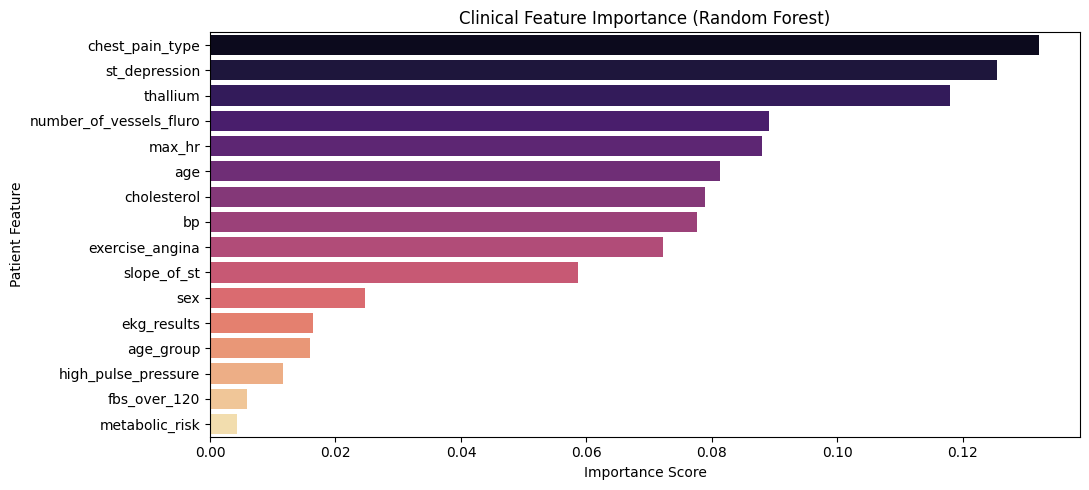

In [146]:
# Reconstruct the exact order of column names as they exist in X_train_advanced(Remember: np.hstack put numeric columns first, then categorical columns!)
advanced_columns = numeric_cols + categorical_cols

importance = pd.DataFrame({
    'Feature': advanced_columns,
    'Importance': rf.feature_importances_
})

#  THE FIX: Permanently sort the DataFrame in descending order
importance = importance.sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.to_string(index=False))

plt.figure(figsize=(11, 5))
sns.barplot(
    data=importance,  # Now Seaborn reads the perfectly sorted rows!
    x="Importance",
    y="Feature",
    palette="magma",
    hue="Feature"
)
plt.title("Clinical Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Patient Feature")
plt.tight_layout()
plt.show()

#### **19. Save Model**

In [147]:
joblib.dump(production_pipeline, "heart_disease_prod_pipeline.pkl")
print("\nModel pipeline successfully saved to disk.")


Model pipeline successfully saved to disk.


**and Load Model**

In [148]:
#Test loading back the exact pipeline structure
loaded_pipeline = joblib.load("heart_disease_prod_pipeline.pkl")
print("Pipeline loaded successfully! Ready for real-world predictions.")

Pipeline loaded successfully! Ready for real-world predictions.


`Easy Flow to Remember`

1. Import Libraries
2. Load Dataset
3. Basic EDA
4. Data Cleaning
5. Visualization analysis
6. Outliers detection
7. Feature Engineering
8. Train-Test Split 
9. Feature scaling & encoding
10. Regression Models
11. Regression Metrics
12. Classification Models
13. Classification Metrics 
14. Cross Validation
15. Feature Selection
16. Hyperparameter Tuning
17. Pipeline 18. Feature Importance
19. Save Model & load model
20. Deployment (Streamlit)